# Test for a single field & tomo bin

In [152]:
import os
os.chdir('/home/hedi/HSCNG/')
import multiprocessing as mp

import numpy as np
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS
from astropy import units as u
import pymaster as nmt
import tqdm

from hsc_y3_utils import map_utils, stats_code
import matplotlib.pyplot as plt

name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
tomo_bin = [1, 2, 3, 4]
pixscale_arcmin = 0.5   # 0.5 arcmin → degrees/pixel
pixscale_deg = pixscale_arcmin / 60.0
smoothing_kernel_size = 1   # arcmin

ell_min = 80
ell_max = 6500
n_bins = 20

# a casual field and tomo bin

In [153]:
field = 'GAMA09H'
tomo = [1, 2, 3, 4]
npro = -1
print(f'Processing field: {field}')
print('Loading data...')

# 1 data loading
npatch = number_patches[name_fields.index(field)]
dats = [
    fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
    for i in range(npatch)
]
dat = np.concatenate(dats)
dat = dat[np.isin(dat['hsc_y3_zbin'], np.atleast_1d(tomo))]

ra = dat['i_ra']
dec = dat['i_dec']
padding = 10

w, (nx, ny) = map_utils.set_wcs_shape(ra, dec, pixscale_arcmin, padding)

print('Image size:', nx, 'x', ny)

Processing field: GAMA09H
Loading data...
Image size: 3060 x 821


# shear map

In [155]:
# 2 shear map
print('Creating shear maps...')

flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)
ra_cat = dat['i_ra']
dec_cat = dat['i_dec']
weight_cat = dat['i_hsmshaperegauss_derived_weight']
m_cat = dat['i_hsmshaperegauss_derived_shear_bias_m']
erms_cat = dat['i_hsmshaperegauss_derived_rms_e']

e1_cat = dat['i_hsmshaperegauss_e1']
e2_cat = dat['i_hsmshaperegauss_e2']
c1_cat = dat['i_hsmshaperegauss_derived_shear_bias_c1']
c2_cat = dat['i_hsmshaperegauss_derived_shear_bias_c2']
flux_cat = dat['i_apertureflux_10_mag']
res_cat = dat['i_hsmshaperegauss_resolution']

psf11 = dat['i_sdssshape_psf_shape11']
psf12 = dat['i_sdssshape_psf_shape12']
psf22 = dat['i_sdssshape_psf_shape22']
epsf1_cat = (psf11 - psf22) / (psf11 + psf22)
epsf2_cat = (2 * psf12) / (psf11 + psf22)

e1_hat, e2_hat = map_utils.calib_shear_y3(
    weight_cat,
    m_cat,
    erms_cat,
    e1_cat,
    e2_cat,
    c1_cat,
    c2_cat,
    flux_cat,
    res_cat,
    epsf1_cat,
    epsf2_cat,
)

[g1_map, g2_map], [mask, _] = map_utils.create_shear_map(
    ra_cat,
    dec_cat,
    e1_hat,
    e2_hat,
    flatgrid,
    weights=weight_cat,
)

mask_z = flatgrid.transform_mapsize(mask)
g1_map = flatgrid.transform_mapsize(g1_map)
g2_map = flatgrid.transform_mapsize(g2_map)

smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)
g1_map_smooth = flatgrid.smooth_G_masked(g1_map, mask_z, smoothing_pixels)
g2_map_smooth = flatgrid.smooth_G_masked(g2_map, mask_z, smoothing_pixels)

Creating shear maps...


Text(0.5, 1.0, 'GAMA09H tomo [1, 2, 3, 4]')

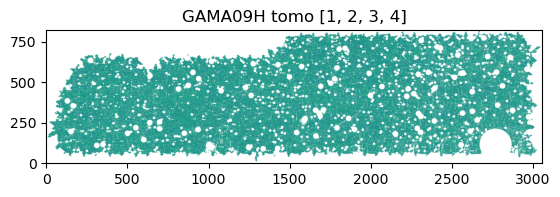

In [156]:
plt.imshow(g1_map_smooth, origin='lower')

shear_plot = np.ma.masked_array(g1_map_smooth, mask=mask_z==0)
cmap = plt.cm.viridis.copy()
cmap.set_bad('white')

plt.imshow(shear_plot, origin='lower', cmap=cmap)
plt.title(f'{field} tomo {tomo}')
# plt.colorbar()

# kappa map
pipeline: smoothing -> inpainting -> KSI -> masking

In [157]:
smooth_g = True
inpainting = True
procedure = []

if smooth_g:
    procedure.append('smooth g')
if inpainting:
    procedure.append('inpainting')
procedure.append('KSI-masking')

procedure_str = '-'.join(procedure)

g1_used = g1_map_smooth if smooth_g else g1_map
g2_used = g2_map_smooth if smooth_g else g2_map

if inpainting:      # maybe consider moving inpainting to the front, and then do smoothing
# Inpainting
    g1_used = map_utils.inpaint(g1_used*mask_z, mask_z, niter=100, thresholding='hard')
    g2_used = map_utils.inpaint(g2_used*mask_z, mask_z, niter=100, thresholding='hard')

# KS inversion
kappa_unmask, kappa_i_unmask = map_utils.KS_map(g1_used, g2_used)

# masking

kappa = mask_z * kappa_unmask
kappa_i = mask_z * kappa_i_unmask

Text(0.5, 1.0, 'GAMA09H tomo [1, 2, 3, 4] smooth g-inpainting-KSI-masking kappa map')

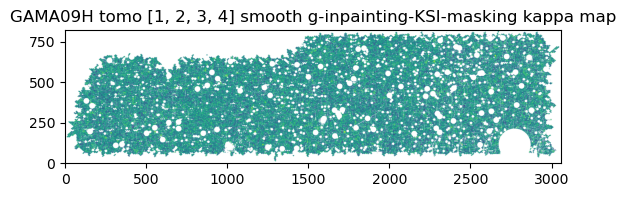

In [158]:
kappa_plot = np.ma.masked_array(kappa, mask=mask_z==0)
cmap = plt.cm.viridis.copy()
cmap.set_bad('white')

plt.imshow(kappa_plot, origin='lower', cmap=cmap)
plt.title(f'{field} tomo {tomo} {procedure_str} kappa map')
# plt.colorbar()

Text(0, 0.5, 'Number of peaks')

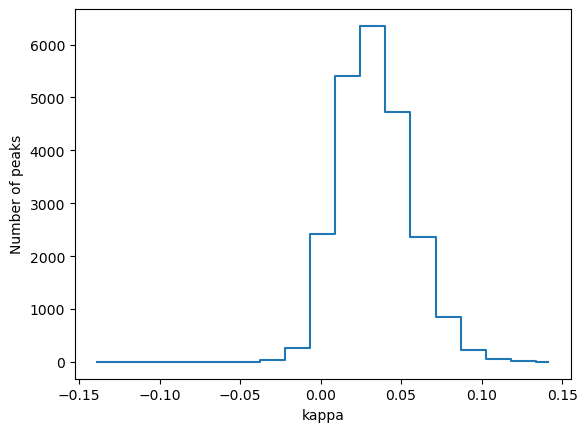

In [161]:
# binning = np.linspace(-3, 3, 20)

count_p, edge = stats_code.peaks_histogram(kappa, mask=mask_z, bins=20)

plt.plot(edge, count_p, drawstyle='steps-mid')
plt.xlabel('kappa')
plt.ylabel('Number of peaks')


# power spectrum calculation
## work space calculation

In [ ]:
size_rad_x = pixscale_deg / 180.0 * np.pi * nx
size_rad_y = pixscale_deg / 180.0 * np.pi * ny
ell_edges = np.unique(np.logspace(np.log10(ell_min), np.log10(ell_max), n_bins))
bins = nmt.bins.NmtBinFlat(ell_edges[:-1], ell_edges[1:])
ells_uncoupled = bins.get_effective_ells()

f0 = nmt.NmtFieldFlat(size_rad_x, size_rad_y, mask_z, [g1_map, -g2_map])
wsp = nmt.NmtWorkspaceFlat()
wsp.compute_coupling_matrix(f0, f0, bins)

## power spectrum of shear

In [12]:
def _compute_power_spectrum_spin2(map01=None,map02=None,mask1=None,lx_rad=None,ly_rad= None,b=None, wsp=None):
    f0 = nmt.NmtFieldFlat(lx_rad,ly_rad, mask1,[map01, map02]) #spin 2    
    #Compute power spectrum
    cl_coupled = nmt.compute_coupled_cell_flat(f0,f0,b)
    cl_uncoupled = wsp.decouple_cell(cl_coupled)

    return cl_uncoupled #EE, EB, BE, BB 

In [11]:
ee, eb, _, bb = _compute_power_spectrum_spin2(g1_map, g2_map, mask_z, size_rad_x, size_rad_y, bins, wsp)
cls_data = {
    'EE': ee,
    'EB': eb,
    'BB': bb,
}

NameError: name '_compute_power_spectrum_spin2' is not defined

## noise subtraction

In [ ]:
# 4 shot noise
n_rand = 100
rand_ee = []
rand_bb = []
rand_eb = []

for i in range(n_rand):
    e1_ran, e2_ran = map_utils.random_rotation(e1_hat, e2_hat)
    [g1_map, g2_map], [mask, _] = map_utils.create_shear_map(
        ra_cat,
        dec_cat,
        e1_ran,
        e2_ran,
        flatgrid,
        weights=weight_cat,
    )
    mask_z = flatgrid.transform_mapsize(mask)
    g1_map = flatgrid.transform_mapsize(g1_map)
    g2_map = flatgrid.transform_mapsize(g2_map)

    ee_r, bb_r, eb_r = _compute_power_spectrum_spin2(g1_map, g2_map, mask_z, size_rad_x, size_rad_y, bins, wsp)
    rand_ee.append(ee_r)
    rand_bb.append(bb_r)
    rand_eb.append(eb_r)


rand_ee = np.array(rand_ee)
rand_bb = np.array(rand_bb)
rand_eb = np.array(rand_eb)

ee_rm = rand_ee.mean(axis=0)
ee_std = rand_ee.std(axis=0)
bb_rm = rand_bb.mean(axis=0)
bb_std = rand_bb.std(axis=0)
eb_rm = rand_eb.mean(axis=0)
eb_std = rand_eb.std(axis=0)

cls_random_mean = {
    'EE': ee_rm,
    'EB': eb_rm,
    'BB': bb_rm,
}

## power spectrum of kappa

In [ ]:
EE, BB, EB = stats_code.compute_ps_spin0_all_terms(kappa, kappa_i, mask.reshape(ny, nx), size_rad_x, size_rad_y, bins, wsp)

## noise subtraction of power spectrum

In [13]:
#TODO

# NG statistics

## PDF

Text(0, 0.5, 'pdf')

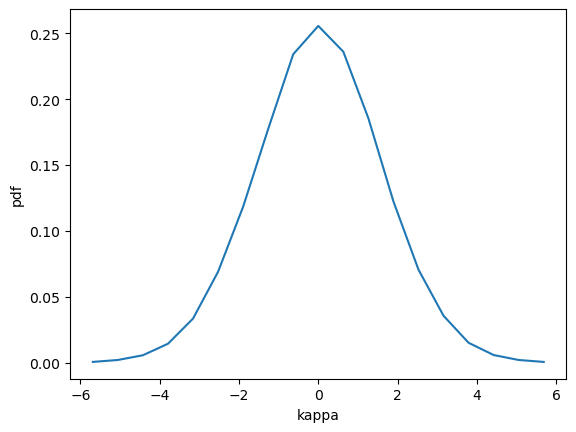

In [12]:
binning = np.linspace(-6, 6, 20)

x, y = stats_code.pdf(kappa, binning, norm=True, mask=mask_z)

plt.plot(x, y)
plt.xlabel('kappa')
plt.ylabel('pdf')

Text(0, 0.5, 'count')

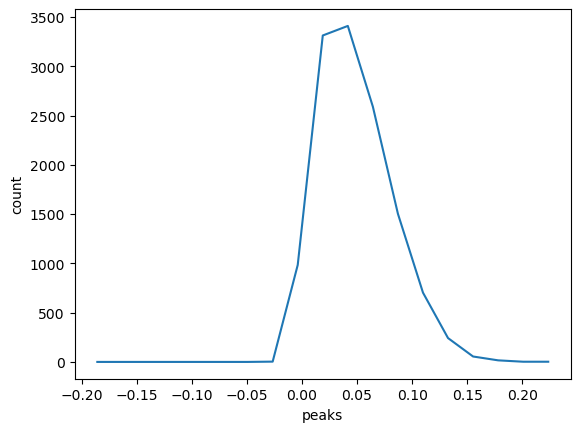

In [24]:
count, edge = stats_code.peaks_histogram(kappa, mask=mask_z, bins=20)
plt.plot(edge, count)

plt.xlabel('peaks')
plt.ylabel('count')

Text(0, 0.5, 'count')

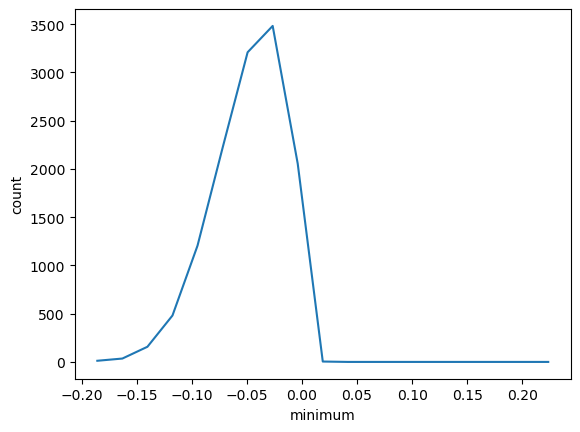

In [23]:
count, edge = stats_code.peaks_histogram(-kappa, mask=mask_z, bins=20)
plt.plot(-edge, count)
plt.xlabel('minimum')
plt.ylabel('count')

In [ ]:
stats_code.MFs(kappa, nu=...)


# Masking discussion

In [14]:
def create_shear_map(ra, dec, g1, g2, flat_obj, weights=None):
    """
    Creates two maps containing the weighted average of the g1, g2 components (spin-2).
    Parameters
    ----------
    ra: right ascention
    dec : declination
    g1 : gamma1 component
    g2 : gamma2 component
    flat_obj: flat object
    weights: galaxy shape weights
    return:
    gamma1 map, gamma2 map, density map and mask
    """
    import copy

    flatmap = flat_obj.pos2pix(ra, dec)
    id_good = flatmap >= 0

    if weights is not None:
        g1 = weights*copy.deepcopy(g1)
        g2 = weights*copy.deepcopy(g2)
    else:
        weights = weights[id_good]

    g1_map = np.bincount(flatmap[id_good],
                       weights= g1[id_good],
                       minlength= flat_obj.get_npix())
    g2_map = np.bincount(flatmap[id_good],
                       weights= g2[id_good],
                       minlength= flat_obj.get_npix())

    g2_map *= (-1.) #apply shear transformation- this is important to be accordingly with the spin definition- see namaster docs, for example!
    weightsmap = np.bincount(flatmap[id_good],
                             weights= weights[id_good],
                             minlength= flat_obj.get_npix())
    weightmask = weightsmap

    nmap = np.bincount(flatmap[id_good],
                       weights=None,
                       minlength=flat_obj.get_npix())

    g1_map[weightsmap != 0] /= weightsmap[weightsmap != 0] #avoid division by zeros
    g2_map[weightsmap != 0] /= weightsmap[weightsmap != 0]

    if weights is not None:
        mask = weightsmap != 0.
        mask = mask.astype('int')
    else:
        mask = weightsmap != 0.
        mask = mask.astype('int')
        weightmask = copy.deepcopy(mask)


    shear_maps = [g1_map, g2_map]
    masks_dens = [mask, nmap, weightmask]

    return shear_maps, masks_dens

In [16]:
[g1_map, g2_map], [mask, nmap, weightmask] = create_shear_map(
    ra_cat,
    dec_cat,
    e1_hat,
    e2_hat,
    flatgrid,
    weights=weight_cat,
)

In [24]:
nmap[nmap>0].min()

np.int64(1)

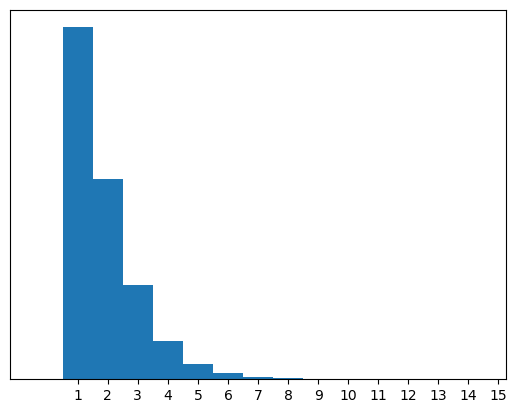

In [29]:
plt.hist(nmap[nmap>0], bins=np.arange(0, 16) - 0.5)
plt.xticks(range(1, 16))
plt.yticks([])
plt.show()

In [66]:
weightmask = flatgrid.transform_mapsize(weightmask)
weightmask_smooth = flatgrid.smooth_G(weightmask, smoothing_pixels)

In [67]:
weightmask_smooth.max()

np.float64(25.137559161003818)

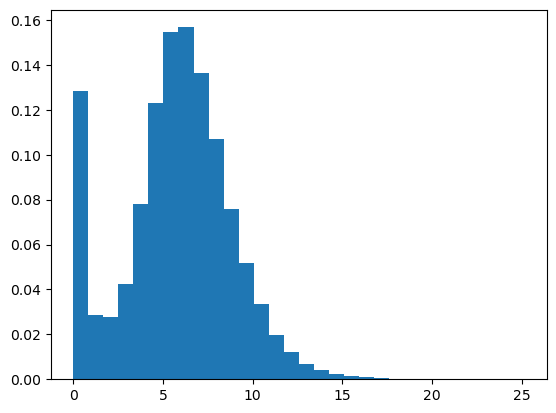

In [68]:
plt.hist(weightmask_smooth[weightmask_smooth > 0], bins=30, density=True)
plt.show()

In [69]:
original_weight = weightmask[weightmask > 0]
smoothed_weight = weightmask_smooth[weightmask_smooth > 0]

print(len(original_weight), len(smoothed_weight))

326135 611887


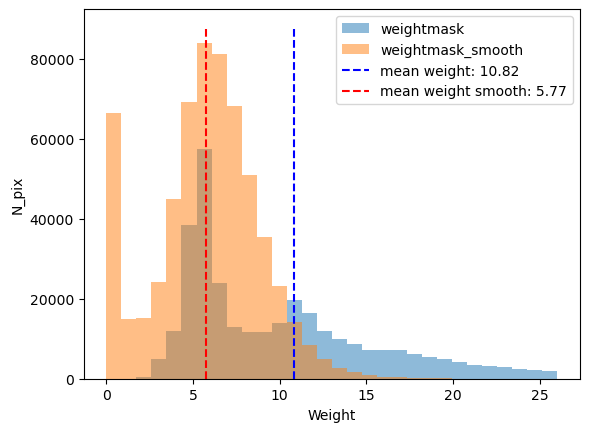

In [82]:
mean_weight = original_weight.mean()
mean_weight_smooth = smoothed_weight.mean()

plt.hist(original_weight, bins=30, range=(0, 26), density=False, label='weightmask', alpha=0.5)

plt.hist(smoothed_weight, bins=30, range=(0, 26), density=False, label='weightmask_smooth', alpha=0.5)

ymax = plt.gca().get_ylim()[1]
plt.vlines(mean_weight, 0, ymax, color='blue', linestyle='--', label=f'mean weight: {mean_weight:.2f}')
plt.vlines(mean_weight_smooth, 0, ymax, color='red', linestyle='--', label=f'mean weight smooth: {mean_weight_smooth:.2f}')

plt.xlabel('Weight')
plt.ylabel('N_pix')
plt.legend()

plt.show()

In [84]:
weight_cat

array([4.82794985, 5.39733573, 3.03324366, ..., 6.97825676, 4.74937942,
       4.44550405], shape=(610104,))

In [59]:
np.percentile(smoothed_weight, 50)

np.float64(5.935434691020451)

In [71]:
print(len(original_weight), (smoothed_weight > criterion).sum())

326135 93423


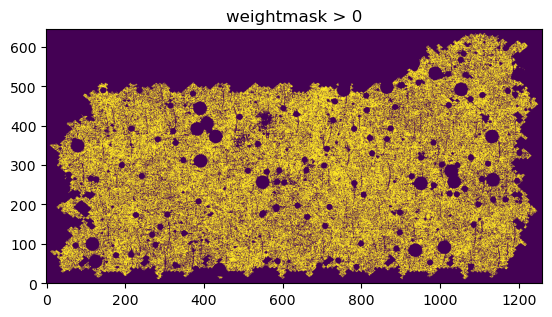

In [79]:
mask_bin = weightmask > 0

plt.title('weightmask > 0')
plt.imshow(mask_bin, origin='lower')

plt.show()

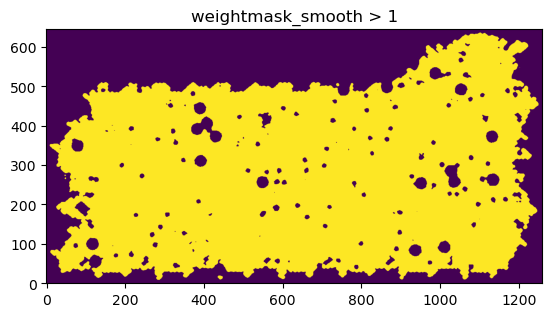

In [78]:
mask_bin = weightmask_smooth > 1

plt.title('weightmask_smooth > 1')
plt.imshow(mask_bin, origin='lower')
plt.show()

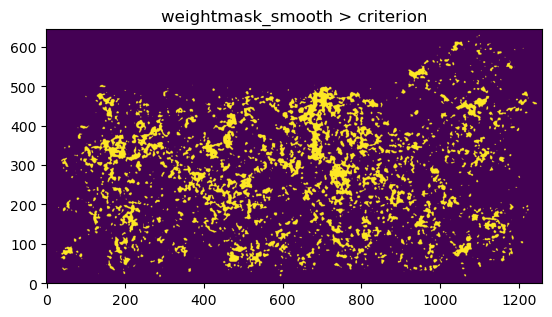

In [80]:
mask_bin = weightmask_smooth > criterion

plt.title('weightmask_smooth > criterion')
plt.imshow(mask_bin, origin='lower')
plt.show()